# Hansen Ames Random Forest comparison → label ChEMBL with the better model (NO hyperparameter tuning)

**Goal:** Load both Hansen Ames-mutagenicity CSVs, clean the molecules, train a **standard 500-tree Random Forest without any hyperparameter search**, load your previous `.joblib` Random Forest, compare both on the **same held-out Hansen test molecules**, choose the higher-scoring RF, then label the ChEMBL dataset using that winner.

- `0` = predicted Ames-negative; `1` = predicted Ames-positive. These are Ames mutagenicity predictions, **not total toxicity**.
- The new RF uses Morgan fingerprints (radius 2, 2048 bits). Configure the old model's actual fingerprint recipe in Section 1.
- **No RandomizedSearchCV, GridSearchCV, or cross-validation-based tuning is performed.**

**Outputs** (inside `OUTPUT_DIR`):
- `new_hansen_rf.joblib` — new 500-tree Random Forest
- `best_ames_rf.joblib` — model selected for ChEMBL labelling
- `rf_comparison_metrics.csv` — comparative Hansen test metrics
- `best_ames_rf_metadata.json` — model selection, fingerprints, caveats
- `chembl_pretrain_labelled.csv` — `Smiles,Ames_prediction`

**Scientific caveats:** The previous RF may already have seen some Hansen test molecules during its earlier training, which would bias its comparison score. If we select the winner based on this test set, its winning score is no longer an entirely unbiased final generalization estimate. Fingerprint parameters for the previous RF must match those used when it was trained.

**Run from top to bottom.** Edit only the paths and any applicable settings in the configuration cell before running.

## 0. Install RDKit if it is missing (optional)

The next **optional** cell shows how to install RDKit into the Python environment used by **this Jupyter kernel**. Uncomment and run it **only if** the dedicated RDKit import cell below raises `ModuleNotFoundError`. Restart the kernel after installing, then run from the top. Other packages must also be installed as needed.

In [1]:
# Uncomment ONLY if RDKit is not already installed in this notebook kernel:
# %pip install rdkit
# If other imports are missing, you can separately install them:
# %pip install pandas numpy scikit-learn joblib matplotlib

## 1. Configuration — enter the four file paths

Both Hansen files are inputs, but they **overlap**; they are deduplicated by canonical molecular structure before splitting. In the original benchmark, `N7090` is tab-separated and `N6512` is comma-separated.

**Old-model compatibility:** `n_features_in_ = 2048` does *not* prove the old RF used Morgan radius 2 or the same RDKit fingerprint implementation. Set `OLD_*` to its *actual original training setup*. If its training recipe is unavailable, treat its metrics and selection as unverified.

**Model-selection metric:** Default is **ROC-AUC**, which scores ranking quality across classification thresholds; change `SELECTION_METRIC` to `F1` if detection of Ames-positive molecules at the model's default classification threshold matters most. Tie-breakers are F1 then Accuracy.

In [2]:
from pathlib import Path

# -------- REQUIRED INPUTS: EDIT THESE FOUR PATHS --------
HANSEN_N7090 = Path('/home/muhamed/repo/CTDDG/datasets/Mutagenicity_N7090.csv')  # tab-separated
HANSEN_N6512 = Path('/home/muhamed/repo/CTDDG/datasets/Mutagenicity_N6512.csv')  # comma-separated
CHEMBL_CSV = Path('/home/muhamed/repo/CTDDG/datasets/data/chembl/chembl.csv')
OLD_RF_JOBLIB = Path('/home/muhamed/repo/CTDDG/REWORKED_CODE/Random_Forest/RF_NItesh.joblib')

# -------- OUTPUTS --------
OUTPUT_DIR = Path('rf_outputs')
NEW_RF_PATH = OUTPUT_DIR / 'new_hansen_rf.joblib'
SELECTED_RF_PATH = OUTPUT_DIR / 'best_ames_rf.joblib'
SELECTION_METADATA_PATH = OUTPUT_DIR / 'best_ames_rf_metadata.json'
COMPARISON_PATH = OUTPUT_DIR / 'rf_comparison_metrics.csv'
LABELLED_CHEMBL_PATH = OUTPUT_DIR / 'chembl_pretrain_labelled.csv'
OVERWRITE_OUTPUTS = False  # True permits replacing old files in OUTPUT_DIR

# -------- NEW RF: FIXED CONFIGURATION; NO TUNING --------
SEED = 42
TEST_SIZE = 0.20
NEW_MORGAN_RADIUS = 2
NEW_MORGAN_BITS = 2048
N_TREES = 500

# -------- HOW TO PICK THE BETTER RF --------
SELECTION_METRIC = 'ROC-AUC'  # choices: 'ROC-AUC', 'F1', 'Accuracy', 'Recall', 'Precision'

# -------- OLD RF: MUST MATCH THE FEATURES IT WAS TRAINED WITH --------
OLD_FINGERPRINT_KIND = 'morgan'  # 'morgan' or 'maccs'
OLD_MORGAN_RADIUS = 2
OLD_MORGAN_BITS = 2048
# If old RF expected additional descriptors, a different Morgan representation,
# or raw SMILES through a Pipeline, adapt feature processing before comparison.

# -------- ChEMBL preprocessing --------
CHEMBL_READ_CHUNK = 50_000
CHEMBL_PREDICT_BATCH = 5_000
STRIP_SALTS = True
CTDDG_SIZE_FILTERS = True  # <=100 atoms, bonds+1 <=120
MAX_ATOMS = 100
MAX_GENERATION_STEPS = 120

print('Configure the four input paths and OLD_* fingerprint settings, then run all cells.')

Configure the four input paths and OLD_* fingerprint settings, then run all cells.


## 2. Import RDKit (dedicated cell)

If this cell says RDKit is missing, run the optional `%pip install rdkit` cell above, restart the kernel, and retry. **Using `%pip` ensures installation in the active Jupyter kernel.**

In [3]:
# RDKit imports — molecular parsing and molecular fingerprints
from rdkit import Chem, DataStructs, RDLogger, rdBase
from rdkit.Chem import MACCSkeys, rdFingerprintGenerator

RDLogger.DisableLog('rdApp.error')
print('RDKit imported successfully! Version:', rdBase.rdkitVersion)

RDKit imported successfully! Version: 2025.09.2


### Remaining imports and input path checks

In [4]:
import json
import time
from collections import Counter

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, classification_report,
    confusion_matrix, f1_score, precision_score, recall_score,
    roc_auc_score, roc_curve,
)
from sklearn.model_selection import train_test_split

print('scikit-learn:', sklearn.__version__)
if SELECTION_METRIC not in ['ROC-AUC', 'F1', 'Accuracy', 'Recall', 'Precision']:
    raise ValueError('Invalid SELECTION_METRIC')
for name, path in [
    ('Hansen N7090', HANSEN_N7090),
    ('Hansen N6512', HANSEN_N6512),
    ('ChEMBL CSV', CHEMBL_CSV),
    ('Previous RF .joblib', OLD_RF_JOBLIB),
]:
    if not path.is_file():
        raise FileNotFoundError(f'{name} not found: {path.resolve()} — edit Section 1')
    print(f'OK  {name}: {path.resolve()}')

all_outputs = [NEW_RF_PATH, SELECTED_RF_PATH, SELECTION_METADATA_PATH,
               COMPARISON_PATH, LABELLED_CHEMBL_PATH]
if not OVERWRITE_OUTPUTS:
    existing = [str(p) for p in all_outputs if p.exists()]
    if existing:
        raise FileExistsError(
            'Output file(s) already exist: ' + ', '.join(existing) +
            '. Change OUTPUT_DIR or set OVERWRITE_OUTPUTS=True.'
        )
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

scikit-learn: 1.3.2
OK  Hansen N7090: /home/muhamed/repo/CTDDG/datasets/Mutagenicity_N7090.csv
OK  Hansen N6512: /home/muhamed/repo/CTDDG/datasets/Mutagenicity_N6512.csv
OK  ChEMBL CSV: /home/muhamed/repo/CTDDG/datasets/data/chembl/chembl.csv
OK  Previous RF .joblib: /home/muhamed/repo/CTDDG/REWORKED_CODE/Random_Forest/RF_NItesh.joblib


## 3. Load and clean Hansen labels

- Read **both** original versions (they overlap; they are not independent datasets).
- Keep only valid RDKit SMILES and binary `Activity` values.
- Canonicalize molecular structures, remove duplicate structures and discard structures carrying conflicting labels.
- **No ML-generated labels are used here**: `Activity` comes from experimental Ames data.

*Note:* removing canonical duplicates can produce a somewhat different final row count from the previous notebook, which deduplicated primarily on original SMILES text. That is deliberate: the same structure should not appear on both sides of the new train/test split.

In [5]:
def read_hansen(path, separator):
    df = pd.read_csv(path, sep=separator)
    df.columns = df.columns.str.strip()
    required = {'Canonical_Smiles', 'Activity'}
    if not required.issubset(df.columns):
        raise ValueError(f'{path}: missing {required - set(df.columns)}. Columns: {list(df.columns)}')
    print(f'{path.name}: {len(df):,} rows')
    return df[['Canonical_Smiles', 'Activity']].copy()

hansen_raw = pd.concat([
    read_hansen(HANSEN_N7090, '\t'),
    read_hansen(HANSEN_N6512, ','),
], ignore_index=True)

hansen_raw['Activity'] = pd.to_numeric(hansen_raw['Activity'], errors='coerce')
hansen_raw = hansen_raw[
    hansen_raw['Canonical_Smiles'].notna() & hansen_raw['Activity'].isin([0, 1])
].copy()

records = []
invalid_smiles = 0
for smi, activity in hansen_raw[['Canonical_Smiles', 'Activity']].itertuples(index=False, name=None):
    mol = Chem.MolFromSmiles(str(smi).strip())
    if mol is None:
        invalid_smiles += 1
        continue
    records.append((Chem.MolToSmiles(mol, canonical=True), int(activity)))

hansen = pd.DataFrame(records, columns=['Smiles', 'Activity'])
conflict_counts = hansen.groupby('Smiles')['Activity'].nunique()
conflicting = set(conflict_counts[conflict_counts > 1].index)
hansen = hansen[~hansen['Smiles'].isin(conflicting)]
hansen = hansen.drop_duplicates(subset=['Smiles']).reset_index(drop=True)

if hansen.empty or hansen['Activity'].nunique() != 2:
    raise ValueError('Hansen has no usable rows or is missing a class after cleaning.')

print(f'Combined raw entries: {len(hansen_raw):,}')
print(f'Invalid SMILES skipped: {invalid_smiles:,}')
print(f'Conflicting unique structures removed: {len(conflicting):,}')
print(f'Final unique labelled molecules: {len(hansen):,}')
print('Class counts (0=negative, 1=positive):', hansen['Activity'].value_counts().sort_index().to_dict())
display(hansen.head())

Mutagenicity_N7090.csv: 7,090 rows
Mutagenicity_N6512.csv: 6,512 rows
Combined raw entries: 13,602
Invalid SMILES skipped: 13
Conflicting unique structures removed: 0
Final unique labelled molecules: 7,082
Class counts (0=negative, 1=positive): {0: 3322, 1: 3760}


,Smiles,Activity
0,COc1cc([N+](=O)[O-])c(O)c(C(C)(C)C)c1,0
1,CC(C)(Cl)Cl,0
2,CC(C)(C)NCC(O)COc1ccccc1C1CCCC1,1
3,CC(C)(C)NC[C@H](O)COc1ccccc1C1CCCC1,1
4,CC(C)(C)[N+](=O)[O-],0


## 4. Morgan fingerprints

New RF features are **Morgan radius 2, 2048 bits**. The old RF uses **its own explicitly configured representation**; both models will still be evaluated on the same *molecule rows*.

In [6]:
_morgan_generators = {}

def make_fingerprints(mols, *, kind='morgan', radius=2, n_bits=2048):
    if kind == 'morgan':
        key = (radius, n_bits)
        if key not in _morgan_generators:
            _morgan_generators[key] = rdFingerprintGenerator.GetMorganGenerator(
                radius=radius, fpSize=n_bits
            )
        get_fp = _morgan_generators[key].GetFingerprint
        width = n_bits
    elif kind == 'maccs':
        get_fp = MACCSkeys.GenMACCSKeys
        width = 167
    else:
        raise ValueError("Fingerprint kind must be 'morgan' or 'maccs'")

    arr = np.empty((len(mols), width), dtype=np.uint8)
    for i, mol in enumerate(mols):
        DataStructs.ConvertToNumpyArray(get_fp(mol), arr[i])
    return arr

mols = [Chem.MolFromSmiles(s) for s in hansen['Smiles']]
X = make_fingerprints(mols, kind='morgan', radius=NEW_MORGAN_RADIUS, n_bits=NEW_MORGAN_BITS)
y = hansen['Activity'].to_numpy(dtype=np.int8)
print(f'New model feature matrix: {X.shape}; target vector: {y.shape}')

New model feature matrix: (7082, 2048); target vector: (7082,)


## 5. Create the held-out Hansen test set

Split cleaned Hansen molecules into **80% training / 20% testing**, stratified by experimental labels. The new RF is trained on the training portion only. Both models are evaluated on the **same test molecules** (though the old model may previously have seen some of those molecules).

In [7]:
all_indices = np.arange(len(hansen))
train_idx, test_idx = train_test_split(
    all_indices, test_size=TEST_SIZE, stratify=y, random_state=SEED
)
X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
print('Training molecules:', len(train_idx), '| Test molecules:', len(test_idx))
print('Test distribution:', pd.Series(y_test).value_counts().sort_index().to_dict())
assert not (set(hansen.iloc[train_idx]['Smiles']) & set(hansen.iloc[test_idx]['Smiles']))

Training molecules: 5665 | Test molecules: 1417
Test distribution: {0: 665, 1: 752}


## 6. Train a new Random Forest (NO hyperparameter tuning)

Train a **500-tree Random Forest** on the 80% Hansen training molecules with `random_state=42` and CPU parallelism (`n_jobs=-1`). There is **no grid search, randomized search, or cross-validation loop**. The 20% Hansen test set is not used for training.

In [8]:
# Fixed configuration: no hyperparameter search, no cross-validation
start_training = time.time()
new_rf = RandomForestClassifier(
    n_estimators=N_TREES,
    random_state=SEED,
    n_jobs=-1,
)
new_rf.fit(X_train, y_train)
print(f'New RF trained ({N_TREES} trees) in {time.time() - start_training:.1f} seconds.')
print('Test molecules have not been used to train the new RF.')

New RF trained (500 trees) in 2.0 seconds.
Test molecules have not been used to train the new RF.


## 7. Load the previous `.joblib` model

We **never retrain or change** the previous model. Verify its expected fingerprint recipe before continuing; matching vector length is not proof of matching fingerprint meaning. If it previously used any of these Hansen molecules for training, its score can be artificially high, and automatically choosing it based on this benchmark may be misleading.

In [9]:
old_rf = joblib.load(OLD_RF_JOBLIB)
print('Old model type:', type(old_rf).__name__)

if not hasattr(old_rf, 'predict_proba'):
    raise TypeError('Previous model must support predict_proba() for ROC-AUC and ROC curves.')

old_width = 167 if OLD_FINGERPRINT_KIND == 'maccs' else OLD_MORGAN_BITS
expected_width = getattr(old_rf, 'n_features_in_', None)
if expected_width is not None and int(expected_width) != old_width:
    raise ValueError(
        f'Old RF expects {expected_width} input features, but configured '
        f'{OLD_FINGERPRINT_KIND} generates {old_width}. Fix the OLD_* settings in Section 1.'
    )

if OLD_FINGERPRINT_KIND == 'morgan' and (
    OLD_MORGAN_RADIUS == NEW_MORGAN_RADIUS and OLD_MORGAN_BITS == NEW_MORGAN_BITS
):
    X_test_old = X_test  # same feature vectors for both models
else:
    X_test_old = make_fingerprints(
        [mols[i] for i in test_idx], kind=OLD_FINGERPRINT_KIND,
        radius=OLD_MORGAN_RADIUS, n_bits=OLD_MORGAN_BITS,
    )

print('Old RF features:', X_test_old.shape[1])
print('ASSUMED old fingerprint:', OLD_FINGERPRINT_KIND,
      '(radius='+str(OLD_MORGAN_RADIUS)+', bits='+str(OLD_MORGAN_BITS)+')'
      if OLD_FINGERPRINT_KIND == 'morgan' else '(167 MACCS bits)')
print('Reminder: previous-RF training overlap with this Hansen test set is UNKNOWN.')

Old model type: RandomForestClassifier
Old RF features: 2048
ASSUMED old fingerprint: morgan (radius=2, bits=2048)
Reminder: previous-RF training overlap with this Hansen test set is UNKNOWN.


## 8. Evaluate both RFs on the **same** held-out molecules

The positive class is `1 = Ames-positive`. We compute Accuracy, Precision, Recall, F1, and ROC-AUC for both models. The old model's training-data overlap with this test set **cannot be assessed from a plain `.joblib` model file**. Scores are comparable descriptively but may not be equally independent.

In [10]:
def get_predictions_and_scores(model, features):
    pred = model.predict(features).astype(int)
    classes = getattr(model, 'classes_', None)
    if classes is None or set(classes.tolist()) != {0, 1}:
        raise ValueError(f'Expected model classes [0, 1], got {classes}')
    pos_idx = np.where(classes == 1)[0][0]
    prob = model.predict_proba(features)[:, pos_idx]
    return pred, prob

new_pred, new_prob = get_predictions_and_scores(new_rf, X_test)
old_pred, old_prob = get_predictions_and_scores(old_rf, X_test_old)

def evaluate(name, predictions, probabilities):
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions, zero_division=0),
        'Recall': recall_score(y_test, predictions, zero_division=0),
        'F1': f1_score(y_test, predictions, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, probabilities),
        'Test samples': len(y_test),
    }

comparison = pd.DataFrame([
    evaluate('New RF (trained here)', new_pred, new_prob),
    evaluate('Previous RF (loaded)', old_pred, old_prob),
]).set_index('Model')
display(comparison.round(4))

for name, preds in [('New RF', new_pred), ('Previous RF', old_pred)]:
    print('\n' + '=' * 60 + f'\n{name} — classification report')
    print(classification_report(y_test, preds, labels=[0, 1],
          target_names=['Ames-negative (0)', 'Ames-positive (1)'], zero_division=0))
    print('Confusion matrix [rows: true; cols: predicted]:\n',
          confusion_matrix(y_test, preds, labels=[0, 1]))

comparison.to_csv(COMPARISON_PATH)
print('\nSaved comparison:', COMPARISON_PATH.resolve())

,Accuracy,Precision,Recall,F1,ROC-AUC,Test samples
Model,,,,,,
New RF (trained here),0.8031,0.8253,0.7979,0.8114,0.8845,1417
Previous RF (loaded),0.9393,0.9382,0.9481,0.9431,0.9776,1417



New RF — classification report
                   precision    recall  f1-score   support

Ames-negative (0)       0.78      0.81      0.79       665
Ames-positive (1)       0.83      0.80      0.81       752

         accuracy                           0.80      1417
        macro avg       0.80      0.80      0.80      1417
     weighted avg       0.80      0.80      0.80      1417

Confusion matrix [rows: true; cols: predicted]:
 [[538 127]
 [152 600]]

Previous RF — classification report
                   precision    recall  f1-score   support

Ames-negative (0)       0.94      0.93      0.93       665
Ames-positive (1)       0.94      0.95      0.94       752

         accuracy                           0.94      1417
        macro avg       0.94      0.94      0.94      1417
     weighted avg       0.94      0.94      0.94      1417

Confusion matrix [rows: true; cols: predicted]:
 [[618  47]
 [ 39 713]]

Saved comparison: /home/muhamed/repo/CTDDG/REWORKED_CODE/Random_Forest/r

### Visual comparison: confusion matrices and ROC curves

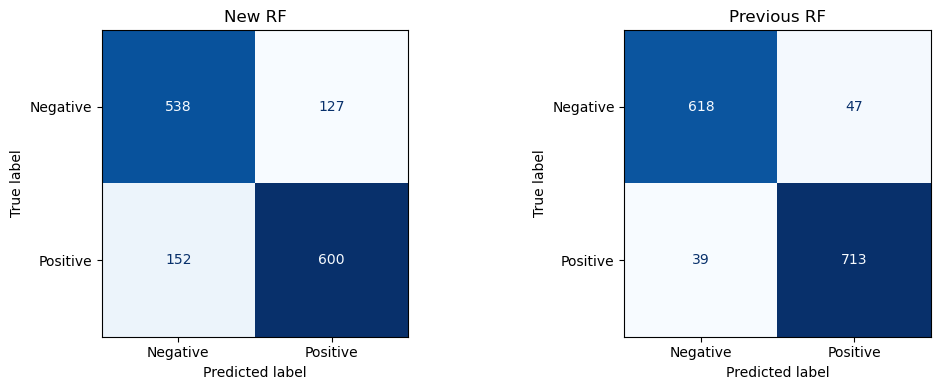

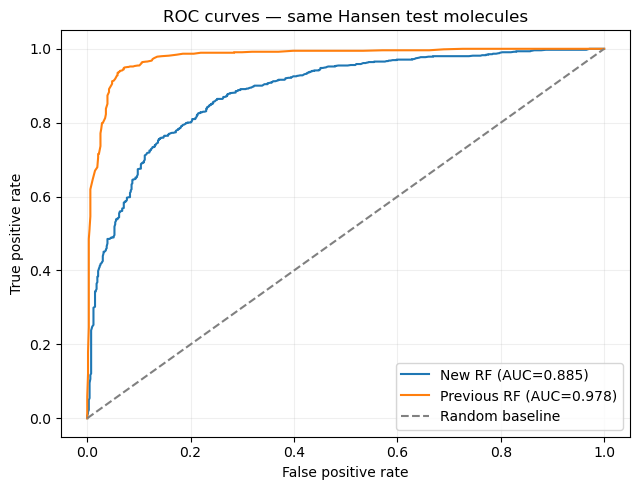

INTERPRETATION WARNING: The previous model may have trained on some or all of
these test molecules. Without its training-data provenance, its score is
a descriptive side-by-side comparison, NOT an independent benchmark.


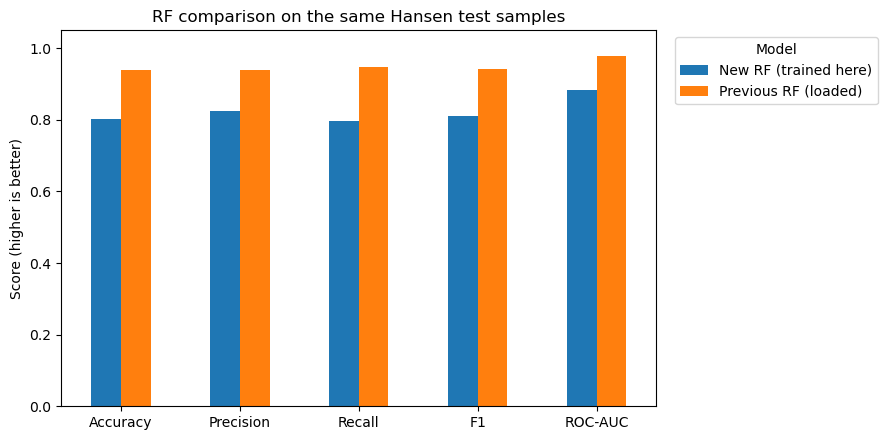

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, preds) in zip(axes, [('New RF', new_pred), ('Previous RF', old_pred)]):
    ConfusionMatrixDisplay.from_predictions(
        y_test, preds, labels=[0, 1], display_labels=['Negative', 'Positive'],
        cmap='Blues', colorbar=False, ax=ax,
    )
    ax.set_title(name)
fig.tight_layout()
plt.show()

plt.figure(figsize=(6.5, 5))
for name, probs in [('New RF', new_prob), ('Previous RF', old_prob)]:
    fpr, tpr, _ = roc_curve(y_test, probs)
    plt.plot(fpr, tpr, label=f'{name} (AUC={roc_auc_score(y_test, probs):.3f})')
plt.plot([0, 1], [0, 1], '--', color='gray', label='Random baseline')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC curves — same Hansen test molecules')
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print('INTERPRETATION WARNING: The previous model may have trained on some or all of')
print('these test molecules. Without its training-data provenance, its score is')
print('a descriptive side-by-side comparison, NOT an independent benchmark.')

# Metric bars for direct comparison
metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']
ax = comparison[metrics_to_plot].T.plot(kind='bar', figsize=(9, 4.5), rot=0)
ax.set_ylabel('Score (higher is better)')
ax.set_ylim(0, 1.05)
ax.set_title('RF comparison on the same Hansen test samples')
ax.legend(title='Model', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


## 9. Choose the better-performing RF, save both models and record details

Choose the RF with the highest score on `SELECTION_METRIC` (default `ROC-AUC`); break ties by F1 then Accuracy. ChEMBL will be labelled with **whichever model wins**, with its correct fingerprint representation.

Save the newly trained RF as `new_hansen_rf.joblib` and the winner as `best_ames_rf.joblib`. The original previous `.joblib` is not changed. The selection metadata records how the winner was chosen.

**Caveat:** Because the test set is used for selection, its winning score is subject to selection bias; and because the older model's training-data overlap is unknown, the comparison may not be strictly fair.

In [12]:
# Choose by the requested metric; stable ordering favors new RF on exact ties.
rank_columns = list(dict.fromkeys([SELECTION_METRIC, 'F1', 'Accuracy']))
ranking = comparison.sort_values(by=rank_columns, ascending=False, kind='stable')
selected_name = ranking.index[0]
selected_is_new = selected_name == 'New RF (trained here)'
selected_rf = new_rf if selected_is_new else old_rf
selected_fingerprint = (
    {'kind': 'morgan', 'radius': NEW_MORGAN_RADIUS, 'n_bits': NEW_MORGAN_BITS}
    if selected_is_new else
    {'kind': OLD_FINGERPRINT_KIND, 'radius': OLD_MORGAN_RADIUS, 'n_bits': OLD_MORGAN_BITS}
)

print('\n' + '=' * 65)
print('SELECTION METRIC:', SELECTION_METRIC)
print('WINNING MODEL:', selected_name)
print(f'WINNING {SELECTION_METRIC}: {comparison.loc[selected_name, SELECTION_METRIC]:.4f}')
print('CHOSEN FINGERPRINT RECIPE:', selected_fingerprint)
print('=' * 65)
if not selected_is_new:
    print('WARNING: Previous model won. Check training overlap and fingerprint settings')
    print('before treating it as the better generalizing RF.')

joblib.dump(new_rf, NEW_RF_PATH)
joblib.dump(selected_rf, SELECTED_RF_PATH)

def json_safe(x):
    if isinstance(x, np.integer): return int(x)
    if isinstance(x, np.floating): return float(x)
    if isinstance(x, np.bool_): return bool(x)
    raise TypeError(f'Not serializable: {type(x)}')

selection_metadata = {
    'selected_model': selected_name,
    'selection_metric': SELECTION_METRIC,
    'selected_model_score': float(comparison.loc[selected_name, SELECTION_METRIC]),
    'selected_fingerprint': selected_fingerprint,
    'new_model_fingerprint': {'kind': 'morgan', 'radius': NEW_MORGAN_RADIUS,
                              'n_bits': NEW_MORGAN_BITS},
    'new_rf_config': {'n_estimators': N_TREES, 'random_state': SEED, 'n_jobs': -1},
    'hyperparameter_tuning': 'not performed',
    'previous_model_original_path': str(OLD_RF_JOBLIB.resolve()),
    'test_fraction': TEST_SIZE,
    'random_seed': SEED,
    'held_out_test_samples': len(y_test),
    'comparison_metrics': comparison.reset_index().to_dict(orient='records'),
    'warning_old_model_overlap': 'Unknown whether previous RF trained on Hansen test molecules',
    'warning_model_selection': 'Winner chosen on test data; winner test score may be optimistically selected',
    'warning_smiles_features': 'Previous RF feature recipe must be manually verified',
    'rdkit_version': rdBase.rdkitVersion,
    'sklearn_version': sklearn.__version__,
}
with open(SELECTION_METADATA_PATH, 'w', encoding='utf-8') as fh:
    json.dump(selection_metadata, fh, indent=2, default=json_safe)
print('New baseline RF saved:', NEW_RF_PATH.resolve())
print('WINNER for ChEMBL saved:', SELECTED_RF_PATH.resolve())
print('Winner metadata saved:', SELECTION_METADATA_PATH.resolve())
print('Previous RF input untouched:', OLD_RF_JOBLIB.resolve())


SELECTION METRIC: ROC-AUC
WINNING MODEL: Previous RF (loaded)
WINNING ROC-AUC: 0.9776
CHOSEN FINGERPRINT RECIPE: {'kind': 'morgan', 'radius': 2, 'n_bits': 2048}
before treating it as the better generalizing RF.


New baseline RF saved: /home/muhamed/repo/CTDDG/REWORKED_CODE/Random_Forest/rf_outputs/new_hansen_rf.joblib
WINNER for ChEMBL saved: /home/muhamed/repo/CTDDG/REWORKED_CODE/Random_Forest/rf_outputs/best_ames_rf.joblib
Winner metadata saved: /home/muhamed/repo/CTDDG/REWORKED_CODE/Random_Forest/rf_outputs/best_ames_rf_metadata.json
Previous RF input untouched: /home/muhamed/repo/CTDDG/REWORKED_CODE/Random_Forest/RF_NItesh.joblib


## 10. Label ChEMBL with **the selected best-scoring RF**

- Read the large ChEMBL CSV in chunks, auto-detecting common delimiters.
- Locate the SMILES column, canonicalize and optionally strip salts, remove invalid or duplicate molecules, apply optional CTDDG size filters.
- **Build the fingerprint type expected by the selected RF.** If the previous RF wins and used MACCS or another Morgan radius/width, use *those* settings.
- Predict `Ames_prediction` and write output in batches, with exactly `Smiles,Ames_prediction`.

This **simplified** data-preparation pipeline does not remove BindingDB ligand overlaps or apply a complete CTDDG-specific atom vocabulary; implement those separately if they are required for the original model's training conditions.

In [13]:
def detect_csv_separator(path):
    with open(path, 'r', encoding='utf-8-sig', errors='replace') as fh:
        header = fh.readline()
    return max([',', ';', '\t'], key=lambda delim: header.count(delim))

def find_smiles_column(columns):
    candidates = {'smiles', 'canonical_smiles', 'canonical smiles', 'smile'}
    for col in columns:
        if str(col).strip().lower() in candidates:
            return col
    raise KeyError(f'No recognizable SMILES column. Available columns: {list(columns)[:30]}')

def normalize_chembl_smiles(value):
    if pd.isna(value) or not str(value).strip():
        return None, 'missing_or_invalid'
    mol = Chem.MolFromSmiles(str(value).strip())
    if mol is None:
        return None, 'missing_or_invalid'
    if STRIP_SALTS:
        fragments = Chem.GetMolFrags(mol, asMols=True, sanitizeFrags=True)
        if fragments:
            mol = max(fragments, key=lambda m: (m.GetNumHeavyAtoms(), m.GetNumAtoms()))
    if CTDDG_SIZE_FILTERS:
        if mol.GetNumAtoms() > MAX_ATOMS:
            return None, 'too_many_atoms'
        if mol.GetNumBonds() + 1 > MAX_GENERATION_STEPS:
            return None, 'too_many_steps'
    return Chem.MolToSmiles(mol, canonical=True), None

separator = detect_csv_separator(CHEMBL_CSV)
print('Labelling ChEMBL with:', selected_name, '| fingerprint:', selected_fingerprint)
print('Detected ChEMBL separator:', repr(separator))

# First read just the CSV header to catch a wrong input before processing millions of rows.
chembl_columns = pd.read_csv(CHEMBL_CSV, sep=separator, nrows=0).columns
smiles_column = find_smiles_column(chembl_columns)
print('ChEMBL SMILES column:', smiles_column)

seen_smiles = set()
stats = Counter()
written = 0
first_write = True

t0 = time.time()
for chunk_no, chunk in enumerate(pd.read_csv(
        CHEMBL_CSV, sep=separator, chunksize=CHEMBL_READ_CHUNK,
        usecols=[smiles_column], dtype={smiles_column: 'string'}, low_memory=False), start=1):
    unique_smiles = []
    for item in chunk[smiles_column]:
        stats['input_rows'] += 1
        canonical, reason = normalize_chembl_smiles(item)
        if reason is not None:
            stats[reason] += 1
            continue
        if canonical in seen_smiles:
            stats['duplicates'] += 1
            continue
        seen_smiles.add(canonical)
        unique_smiles.append(canonical)

    for offset in range(0, len(unique_smiles), CHEMBL_PREDICT_BATCH):
        sub_smiles = unique_smiles[offset:offset + CHEMBL_PREDICT_BATCH]
        sub_mols = [Chem.MolFromSmiles(s) for s in sub_smiles]
        X_ch = make_fingerprints(sub_mols, **selected_fingerprint)
        # IMPORTANT: selected_rf is the winner of the Hansen comparison
        pred = selected_rf.predict(X_ch).astype(np.int8)
        out = pd.DataFrame({'Smiles': sub_smiles, 'Ames_prediction': pred})
        out.to_csv(LABELLED_CHEMBL_PATH, index=False,
                   mode='w' if first_write else 'a', header=first_write)
        first_write = False
        written += len(out)
        stats['label_0'] += int((pred == 0).sum())
        stats['label_1'] += int((pred == 1).sum())

    print(f'Chunk {chunk_no}: read {stats["input_rows"]:,}; labelled {written:,}; '
          f'elapsed {time.time()-t0:.1f}s')

if first_write:  # no usable molecules: create a CSV with its expected columns
    pd.DataFrame(columns=['Smiles', 'Ames_prediction']).to_csv(LABELLED_CHEMBL_PATH, index=False)

print('\nChEMBL labeling complete')
print('Output:', LABELLED_CHEMBL_PATH.resolve())
for name in ('input_rows', 'missing_or_invalid', 'too_many_atoms', 'too_many_steps',
             'duplicates', 'label_0', 'label_1'):
    print(f'{name:>20}: {stats[name]:,}')
print('Total labelled:', written)
if written == 0:
    raise RuntimeError('No ChEMBL molecules survived filtering; inspect paths and filters.')

Labelling ChEMBL with: Previous RF (loaded) | fingerprint: {'kind': 'morgan', 'radius': 2, 'n_bits': 2048}
Detected ChEMBL separator: ';'
ChEMBL SMILES column: Smiles
Chunk 1: read 50,000; labelled 49,711; elapsed 30.4s
Chunk 2: read 100,000; labelled 98,978; elapsed 60.0s
Chunk 3: read 150,000; labelled 148,302; elapsed 90.3s
Chunk 4: read 200,000; labelled 197,167; elapsed 121.0s
Chunk 5: read 250,000; labelled 246,148; elapsed 151.4s
Chunk 6: read 300,000; labelled 295,126; elapsed 182.4s
Chunk 7: read 350,000; labelled 343,596; elapsed 213.0s
Chunk 8: read 400,000; labelled 392,273; elapsed 244.4s
Chunk 9: read 450,000; labelled 440,390; elapsed 275.2s
Chunk 10: read 500,000; labelled 486,658; elapsed 305.5s
Chunk 11: read 550,000; labelled 534,571; elapsed 336.3s
Chunk 12: read 600,000; labelled 582,792; elapsed 367.4s
Chunk 13: read 650,000; labelled 629,977; elapsed 398.2s


[20:03:57] WARNING: not removing hydrogen atom without neighbors


Chunk 14: read 700,000; labelled 676,994; elapsed 429.3s
Chunk 15: read 750,000; labelled 724,895; elapsed 460.6s
Chunk 16: read 800,000; labelled 771,916; elapsed 492.2s
Chunk 17: read 850,000; labelled 819,094; elapsed 523.8s
Chunk 18: read 900,000; labelled 866,737; elapsed 555.6s


[20:06:47] WARNING: not removing hydrogen atom without neighbors


Chunk 19: read 950,000; labelled 914,394; elapsed 587.3s
Chunk 20: read 1,000,000; labelled 962,006; elapsed 618.6s
Chunk 21: read 1,050,000; labelled 1,009,584; elapsed 650.0s
Chunk 22: read 1,100,000; labelled 1,056,821; elapsed 681.1s
Chunk 23: read 1,150,000; labelled 1,104,291; elapsed 712.7s
Chunk 24: read 1,200,000; labelled 1,151,489; elapsed 743.8s
Chunk 25: read 1,207,360; labelled 1,158,233; elapsed 748.3s

ChEMBL labeling complete
Output: /home/muhamed/repo/CTDDG/REWORKED_CODE/Random_Forest/rf_outputs/chembl_pretrain_labelled.csv
          input_rows: 1,207,360
  missing_or_invalid: 3
      too_many_atoms: 0
      too_many_steps: 0
          duplicates: 49,124
             label_0: 828,808
             label_1: 329,425
Total labelled: 1158233


## 11. Verify the output files and inspect the selected model

The final ChEMBL labels come from the **winner stored at `SELECTED_RF_PATH`**, not necessarily the newly trained model. The JSON metadata tells you which model won and what fingerprint configuration to use when loading it later.

In [14]:
labelled_check = pd.read_csv(LABELLED_CHEMBL_PATH, nrows=10)
assert list(labelled_check.columns) == ['Smiles', 'Ames_prediction']
assert set(labelled_check['Ames_prediction'].dropna().astype(int).unique()) <= {0, 1}
for path in (NEW_RF_PATH, SELECTED_RF_PATH, SELECTION_METADATA_PATH,
             COMPARISON_PATH, LABELLED_CHEMBL_PATH):
    assert path.is_file(), f'Missing output: {path}'
with open(SELECTION_METADATA_PATH, encoding='utf-8') as fh:
    saved_metadata = json.load(fh)
assert saved_metadata['selected_model'] == selected_name
assert saved_metadata['selected_fingerprint'] == selected_fingerprint

# Sanity check: selected saved model reproduces its test predictions
reloaded_winner = joblib.load(SELECTED_RF_PATH)
selected_X_test = X_test if selected_is_new else X_test_old
expected_winner_pred = new_pred if selected_is_new else old_pred
assert np.array_equal(reloaded_winner.predict(selected_X_test), expected_winner_pred)

print('Success — all five outputs exist:')
for path in (NEW_RF_PATH, SELECTED_RF_PATH, SELECTION_METADATA_PATH,
             COMPARISON_PATH, LABELLED_CHEMBL_PATH):
    print(' ', path.resolve())
print('Selected model:', selected_name)
print('Selected metric:', SELECTION_METRIC)
print('Selected feature configuration:', selected_fingerprint)
print('\nHansen test performance (same held-out molecules):')
display(comparison.round(4))
print('\nLabelled ChEMBL preview:')
display(labelled_check)
print('\nChEMBL values are predicted Ames mutagenicity, NOT experimental ground truth.')

Success — all five outputs exist:
  /home/muhamed/repo/CTDDG/REWORKED_CODE/Random_Forest/rf_outputs/new_hansen_rf.joblib
  /home/muhamed/repo/CTDDG/REWORKED_CODE/Random_Forest/rf_outputs/best_ames_rf.joblib
  /home/muhamed/repo/CTDDG/REWORKED_CODE/Random_Forest/rf_outputs/best_ames_rf_metadata.json
  /home/muhamed/repo/CTDDG/REWORKED_CODE/Random_Forest/rf_outputs/rf_comparison_metrics.csv
  /home/muhamed/repo/CTDDG/REWORKED_CODE/Random_Forest/rf_outputs/chembl_pretrain_labelled.csv
Selected model: Previous RF (loaded)
Selected metric: ROC-AUC
Selected feature configuration: {'kind': 'morgan', 'radius': 2, 'n_bits': 2048}

Hansen test performance (same held-out molecules):


,Accuracy,Precision,Recall,F1,ROC-AUC,Test samples
Model,,,,,,
New RF (trained here),0.8031,0.8253,0.7979,0.8114,0.8845,1417
Previous RF (loaded),0.9393,0.9382,0.9481,0.9431,0.9776,1417



Labelled ChEMBL preview:


,Smiles,Ames_prediction
0,Cc1ccc(CCN2CC(C(=O)NCc3cccnc3)CC2=O)cc1,0
1,O=C1NCCN1c1ccc(S(=O)(=O)Oc2ccc(F)cc2)cc1,0
2,CCOC(=O)c1c(C)oc2nc(C)nc(NCC3CCN(Cc4ccc(F)cc4)...,1
3,Cn1cccc/c1=N\C1CC1,0
4,CCCCc1ccc(NC(=S)NN2CCN(C)CC2)cc1,0
5,O=C(c1ccccc1)c1cccc(/C=c2\[nH]c(=O)/c(=C/c3ccc...,0
6,CC1(C)CC(N(CCc2ccccc2)Cc2ccccc2)CCO1,0
7,CC(=O)N1CCCc2cc(S(=O)(=O)N3CCCC(C(=O)NCc4ccccc...,0
8,O=C(Nc1ccccc1Cl)N1CCN(Cc2cnc3ccccc3c2)CC1,0
9,NCc1ccccc1C(=O)O,0



ChEMBL values are predicted Ames mutagenicity, NOT experimental ground truth.
